# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The NBA Closing Dataset](https://www.kaggle.com/datasets/minmaxer/nba-closing-lines-ats-2024-25)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('nba_2024_25_closing_lines_ats.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,game_id,date_et,start_time_utc,season,season_type,stage,round,home_team,away_team,home_team_id,away_team_id,home_score,away_score,overtime,bookmakers,open_home_win_prob,close_home_win_prob,close_fair_home_odds,close_fair_away_odds,open_spread_home,close_spread_home,close_home_cover_prob,open_total,close_total,close_over_prob,moneyline_winner,favorite,favorite_won,ats_result,ats_margin,ats_result_open,total_result,total_margin,total_result_open
0,0ptyAqOi,2024-10-22,2024-10-22T23:30:00Z,2024-25,regular,Regular season,NaN,Boston Celtics,New York Knicks,KYD9hVEm,WCNO4nbt,132,109,False,15,0.6388,0.6729,1.486,3.057,-4.5,-6.5,0.4828,222.5,221.5,0.5000,home,home,True,home,16.5,home,over,19.5,over
1,MaUq8Nh4,2024-10-22,2024-10-23T02:00:00Z,2024-25,regular,Regular season,NaN,Los Angeles Lakers,Minnesota Timberwolves,ngegZ8bg,KjBIVQcI,110,103,False,15,0.5000,0.4868,2.054,1.949,1.5,1.5,0.5146,224.5,223.5,0.5066,home,away,False,home,8.5,home,under,-10.5,under
2,UPXi61NG,2024-10-23,2024-10-23T23:00:00Z,2024-25,regular,Regular season,NaN,Detroit Pistons,Indiana Pacers,UcjMRj6J,YPohMUTt,109,115,False,15,0.3310,0.3396,2.944,1.514,5.5,5.5,0.4947,233.5,235.5,0.5026,away,away,True,away,-0.5,away,under,-11.5,under
3,06HBMM7c,2024-10-23,2024-10-23T23:30:00Z,2024-25,regular,Regular season,NaN,Philadelphia 76ers,Milwaukee Bucks,vwRW2QSh,QTBEW6rC,109,124,False,15,0.6124,0.3926,2.547,1.646,-4.5,4.0,0.5026,225.5,222.5,0.5000,away,away,True,away,-11.0,away,over,10.5,over
4,C8yVSGtp,2024-10-23,2024-10-23T23:30:00Z,2024-25,regular,Regular season,NaN,Toronto Raptors,Cleveland Cavaliers,CxtbCMdU,xGk13Tb6,106,136,False,15,0.4020,0.3182,3.143,1.467,3.5,6.5,0.5013,218.5,224.5,0.5094,away,away,True,away,-23.5,away,over,17.5,over


## last Five row

In [4]:
df.tail()

,game_id,date_et,start_time_utc,season,season_type,stage,round,home_team,away_team,home_team_id,away_team_id,home_score,away_score,overtime,bookmakers,open_home_win_prob,close_home_win_prob,close_fair_home_odds,close_fair_away_odds,open_spread_home,close_spread_home,close_home_cover_prob,open_total,close_total,close_over_prob,moneyline_winner,favorite,favorite_won,ats_result,ats_margin,ats_result_open,total_result,total_margin,total_result_open
1309,xCQ1NYN6,2025-06-11,2025-06-12T00:30:00Z,2024-25,postseason,Playoffs,NBA Finals,Indiana Pacers,Oklahoma City Thunder,YPohMUTt,0fHFHEWD,116,107,False,18,0.3632,0.3425,2.920,1.521,4.5,5.5,0.5105,227.5,226.5,0.5000,home,away,False,home,14.5,home,under,-3.5,under
1310,UJr9LChJ,2025-06-13,2025-06-14T00:30:00Z,2024-25,postseason,Playoffs,NBA Finals,Indiana Pacers,Oklahoma City Thunder,YPohMUTt,0fHFHEWD,104,111,False,19,0.3357,0.3287,3.042,1.490,5.5,6.5,0.5170,225.5,227.5,0.5000,away,away,True,away,-0.5,away,under,-12.5,under
1311,vwOOlokg,2025-06-16,2025-06-17T00:30:00Z,2024-25,postseason,Playoffs,NBA Finals,Oklahoma City Thunder,Indiana Pacers,0fHFHEWD,YPohMUTt,120,109,False,18,0.7664,0.7619,1.312,4.200,-9.5,-9.5,0.4895,224.5,223.5,0.4909,home,home,True,home,1.5,home,over,5.5,over
1312,O8I9XglL,2025-06-19,2025-06-20T00:30:00Z,2024-25,postseason,Playoffs,NBA Finals,Indiana Pacers,Oklahoma City Thunder,YPohMUTt,0fHFHEWD,108,91,False,19,0.3429,0.3412,2.931,1.518,5.5,5.5,0.4987,224.5,222.5,0.5000,home,away,False,home,22.5,home,under,-23.5,under
1313,YasLoKTi,2025-06-22,2025-06-23T00:00:00Z,2024-25,postseason,Playoffs,NBA Finals,Oklahoma City Thunder,Indiana Pacers,0fHFHEWD,YPohMUTt,103,91,False,19,0.7440,0.6935,1.442,3.263,-8.5,-6.5,0.5066,214.5,215.5,0.5000,home,home,True,home,5.5,home,under,-21.5,under


## Shape of our dataset

In [5]:
df.shape

(1314, 34)

## List out all columns

In [6]:
df.columns

Index(['game_id', 'date_et', 'start_time_utc', 'season', 'season_type',
       'stage', 'round', 'home_team', 'away_team', 'home_team_id',
       'away_team_id', 'home_score', 'away_score', 'overtime', 'bookmakers',
       'open_home_win_prob', 'close_home_win_prob', 'close_fair_home_odds',
       'close_fair_away_odds', 'open_spread_home', 'close_spread_home',
       'close_home_cover_prob', 'open_total', 'close_total', 'close_over_prob',
       'moneyline_winner', 'favorite', 'favorite_won', 'ats_result',
       'ats_margin', 'ats_result_open', 'total_result', 'total_margin',
       'total_result_open'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

game_id                   object
date_et                   object
start_time_utc            object
season                    object
season_type               object
stage                     object
round                     object
home_team                 object
away_team                 object
home_team_id              object
away_team_id              object
home_score                 int64
away_score                 int64
overtime                    bool
bookmakers                 int64
open_home_win_prob       float64
close_home_win_prob      float64
close_fair_home_odds     float64
close_fair_away_odds     float64
open_spread_home         float64
close_spread_home        float64
close_home_cover_prob    float64
open_total               float64
close_total              float64
close_over_prob          float64
moneyline_winner          object
favorite                  object
favorite_won              object
ats_result                object
ats_margin               float64
ats_result

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1314 entries, 0 to 1313
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   game_id                1314 non-null   object 
 1   date_et                1314 non-null   object 
 2   start_time_utc         1314 non-null   object 
 3   season                 1314 non-null   object 
 4   season_type            1314 non-null   object 
 5   stage                  1314 non-null   object 
 6   round                  90 non-null     object 
 7   home_team              1314 non-null   object 
 8   away_team              1314 non-null   object 
 9   home_team_id           1314 non-null   object 
 10  away_team_id           1314 non-null   object 
 11  home_score             1314 non-null   int64  
 12  away_score             1314 non-null   int64  
 13  overtime               1314 non-null   bool   
 14  bookmakers             1314 non-null   int64  
 15  open

## Check Null Value

In [9]:
df.isnull().sum()

game_id                     0
date_et                     0
start_time_utc              0
season                      0
season_type                 0
stage                       0
round                    1224
home_team                   0
away_team                   0
home_team_id                0
away_team_id                0
home_score                  0
away_score                  0
overtime                    0
bookmakers                  0
open_home_win_prob          0
close_home_win_prob         0
close_fair_home_odds        0
close_fair_away_odds        0
open_spread_home            0
close_spread_home           0
close_home_cover_prob       0
open_total                  0
close_total                 0
close_over_prob             0
moneyline_winner            0
favorite                    6
favorite_won                6
ats_result                  0
ats_margin                  0
ats_result_open             0
total_result                0
total_margin                0
total_resu

## Drop Round Feacher

In [10]:
df.drop('round', axis=1, inplace=True)

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,home_score,away_score,bookmakers,open_home_win_prob,close_home_win_prob,close_fair_home_odds,close_fair_away_odds,open_spread_home,close_spread_home,close_home_cover_prob,open_total,close_total,close_over_prob,ats_margin,total_margin
count,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000,1314.000000
mean,114.466514,112.604262,16.398021,0.556548,0.552482,2.286107,3.046775,-2.016743,-1.943303,0.500069,226.196347,226.210807,0.499839,-0.081050,0.859970
std,12.631065,12.874644,0.725362,0.201708,0.212509,1.471656,2.074227,7.349305,7.815953,0.008752,8.540854,9.132919,0.005719,13.756273,17.597541
min,79.000000,67.000000,14.000000,0.090900,0.095000,1.067000,1.105000,-21.500000,-23.500000,0.464800,196.500000,196.500000,0.437100,-46.500000,-49.500000
25%,105.000000,104.000000,16.000000,0.401625,0.377275,1.374500,1.605500,-7.500000,-7.500000,0.493400,220.500000,220.500000,0.497400,-8.500000,-11.500000
50%,115.000000,113.000000,17.000000,0.569750,0.571400,1.750000,2.333000,-2.500000,-2.500000,0.500000,226.500000,226.500000,0.500000,0.500000,1.500000
75%,123.000000,121.000000,17.000000,0.718625,0.727550,2.650750,3.670750,3.500000,4.500000,0.507200,232.500000,232.500000,0.502600,8.500000,12.500000
max,155.000000,162.000000,19.000000,0.940600,0.936900,10.524000,15.851000,17.500000,17.500000,0.535200,251.500000,253.500000,0.520800,49.500000,64.500000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

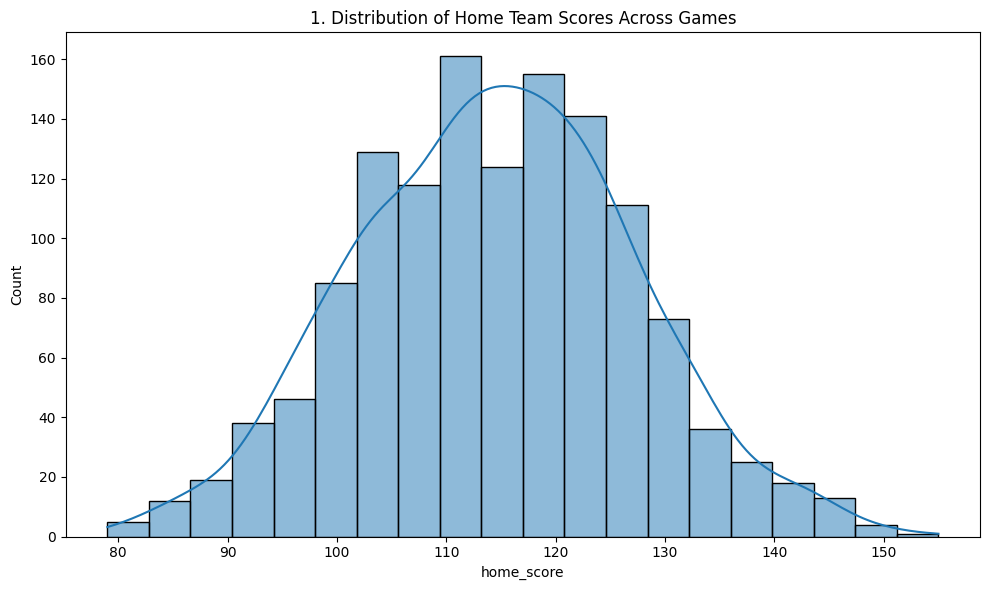

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='home_score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Home Team Scores Across Games')
show_fig()
plot_no += 1

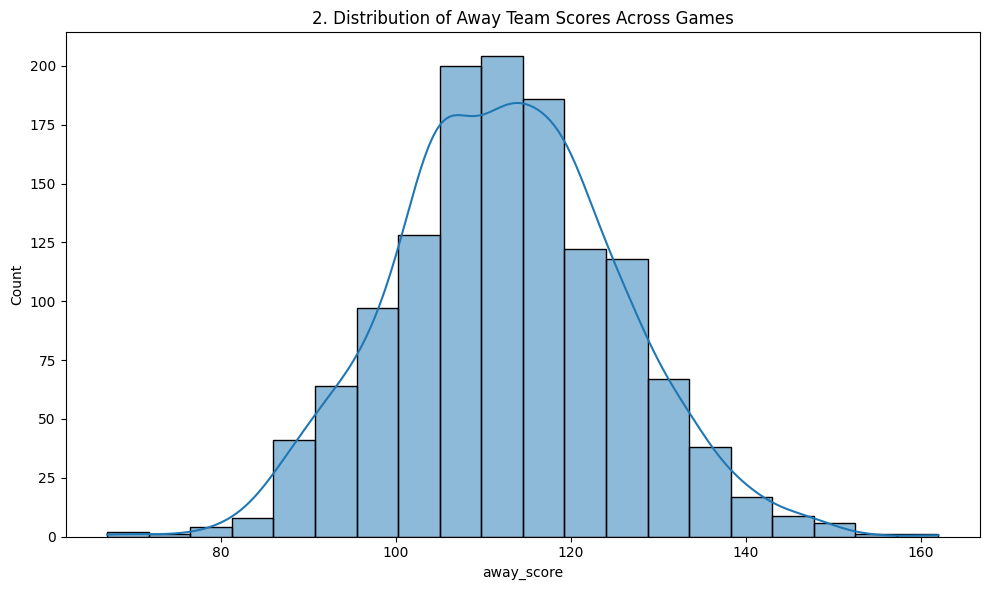

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='away_score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Away Team Scores Across Games')
show_fig()
plot_no += 1

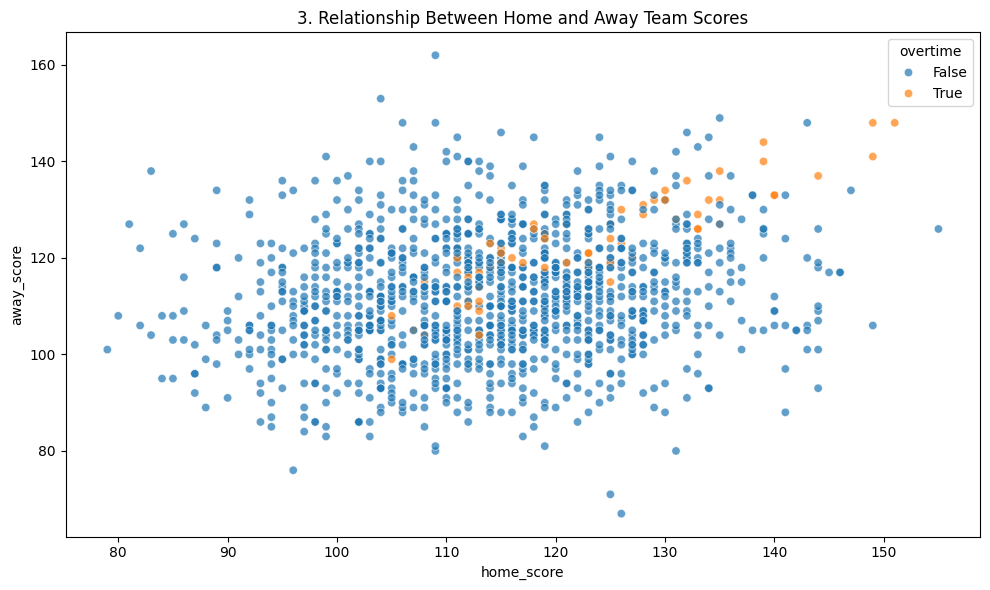

In [16]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='home_score', y='away_score', hue='overtime', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Home and Away Team Scores')
show_fig()
plot_no += 1

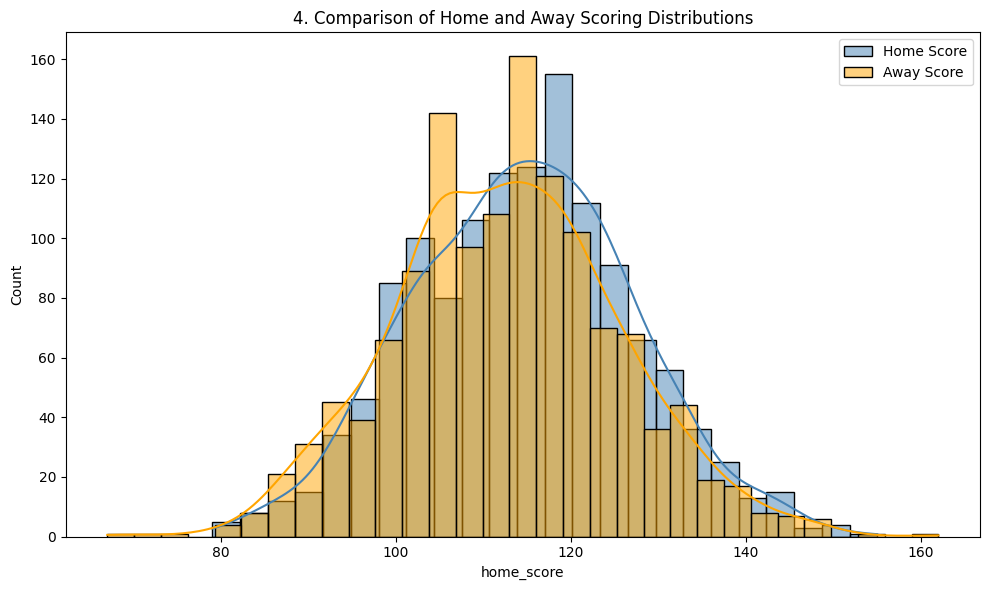

In [17]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='home_score', color='steelblue', label='Home Score', kde=True, alpha=0.5)
sns.histplot(data=df, x='away_score', color='orange', label='Away Score', kde=True, alpha=0.5)
plt.legend()
plt.title(f'{plot_no}. Comparison of Home and Away Scoring Distributions')
show_fig()
plot_no += 1

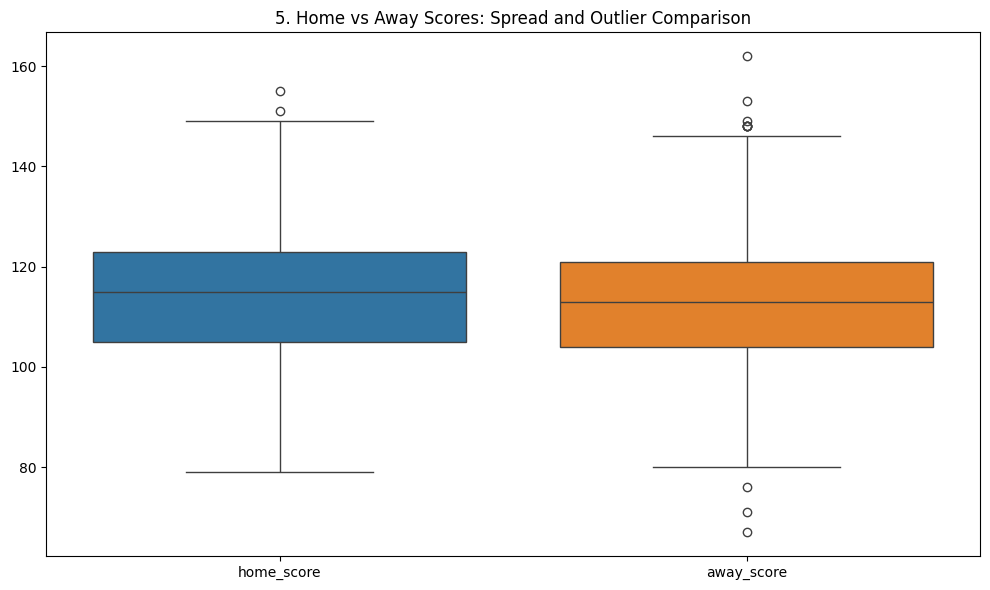

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df[['home_score', 'away_score']])
plt.title(f'{plot_no}. Home vs Away Scores: Spread and Outlier Comparison')
show_fig()
plot_no += 1

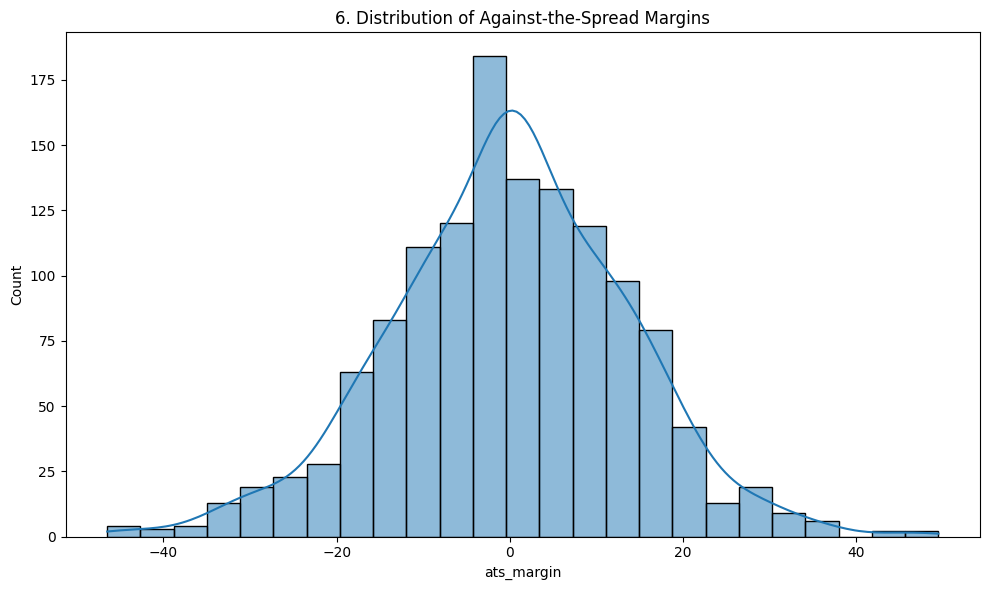

In [19]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='ats_margin', kde=True, bins=25)
plt.title(f'{plot_no}. Distribution of Against-the-Spread Margins')
show_fig()
plot_no += 1

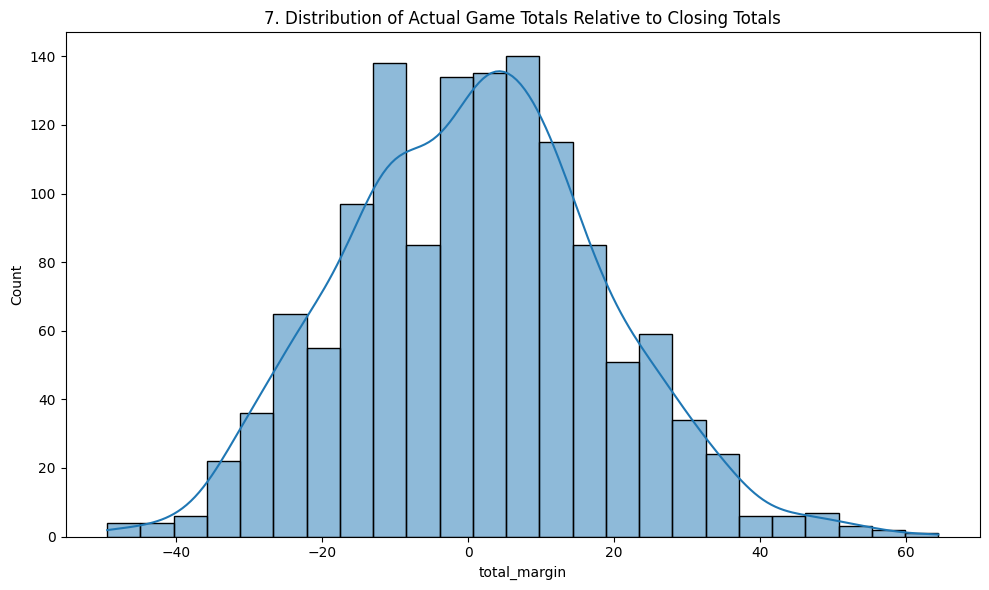

In [20]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='total_margin', kde=True, bins=25)
plt.title(f'{plot_no}. Distribution of Actual Game Totals Relative to Closing Totals')
show_fig()
plot_no += 1

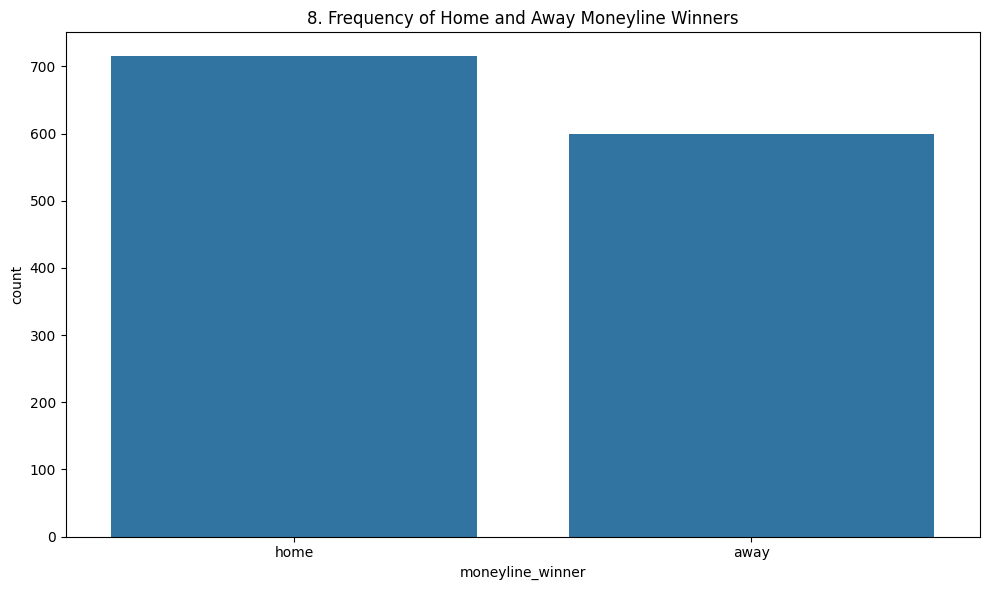

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='moneyline_winner', order=df['moneyline_winner'].value_counts().index)
plt.title(f'{plot_no}. Frequency of Home and Away Moneyline Winners')
show_fig()
plot_no += 1

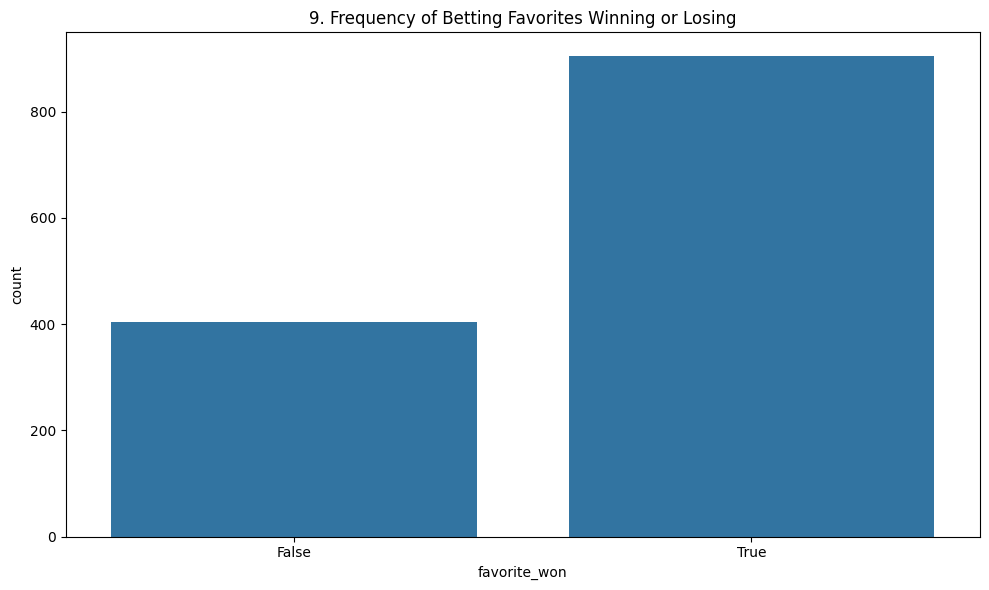

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='favorite_won')
plt.title(f'{plot_no}. Frequency of Betting Favorites Winning or Losing')
show_fig()
plot_no += 1

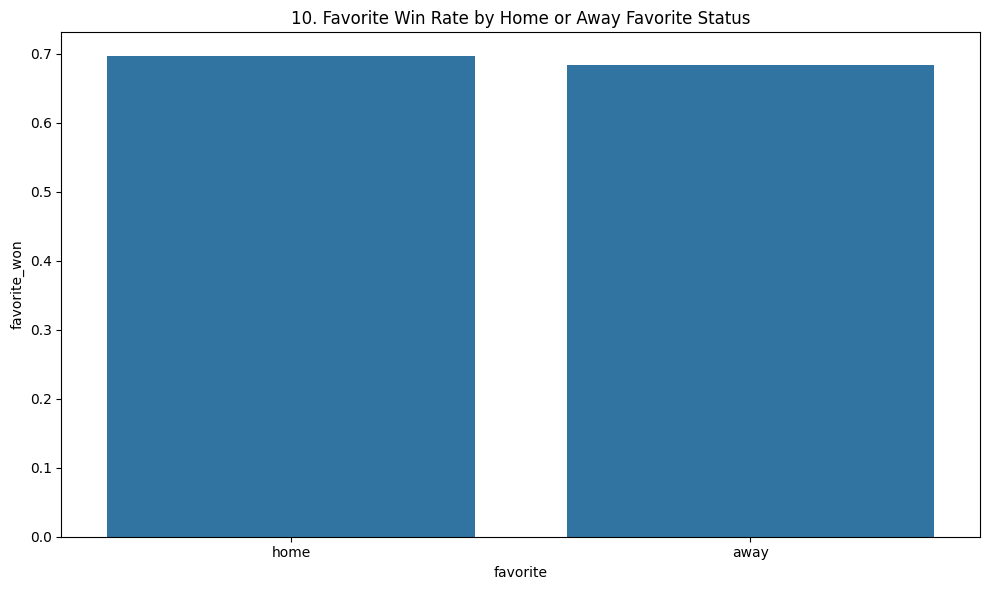

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='favorite', y='favorite_won', errorbar=None)
plt.title(f'{plot_no}. Favorite Win Rate by Home or Away Favorite Status')
show_fig()
plot_no += 1

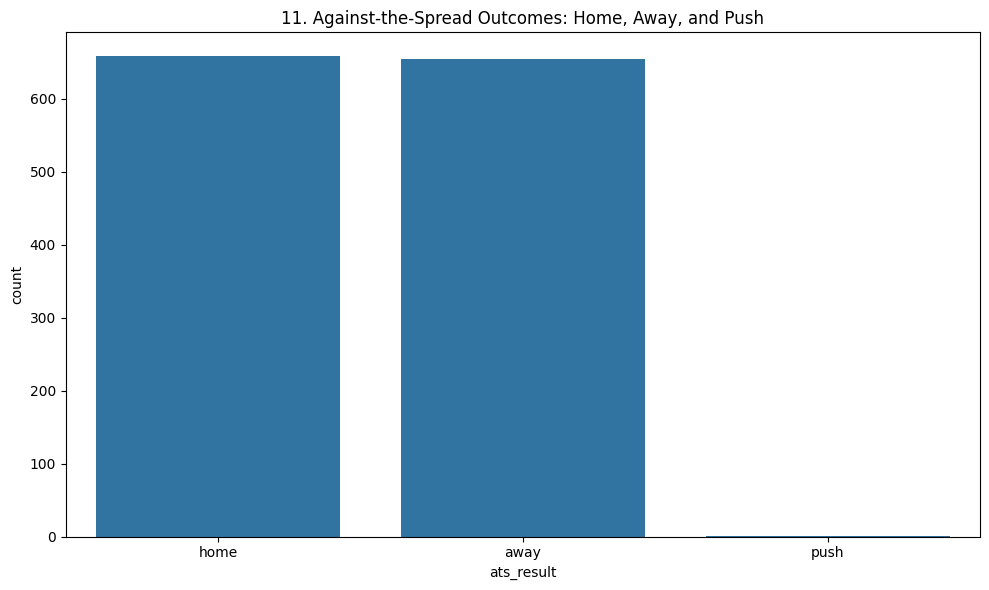

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='ats_result', order=df['ats_result'].value_counts().index)
plt.title(f'{plot_no}. Against-the-Spread Outcomes: Home, Away, and Push')
show_fig()
plot_no += 1

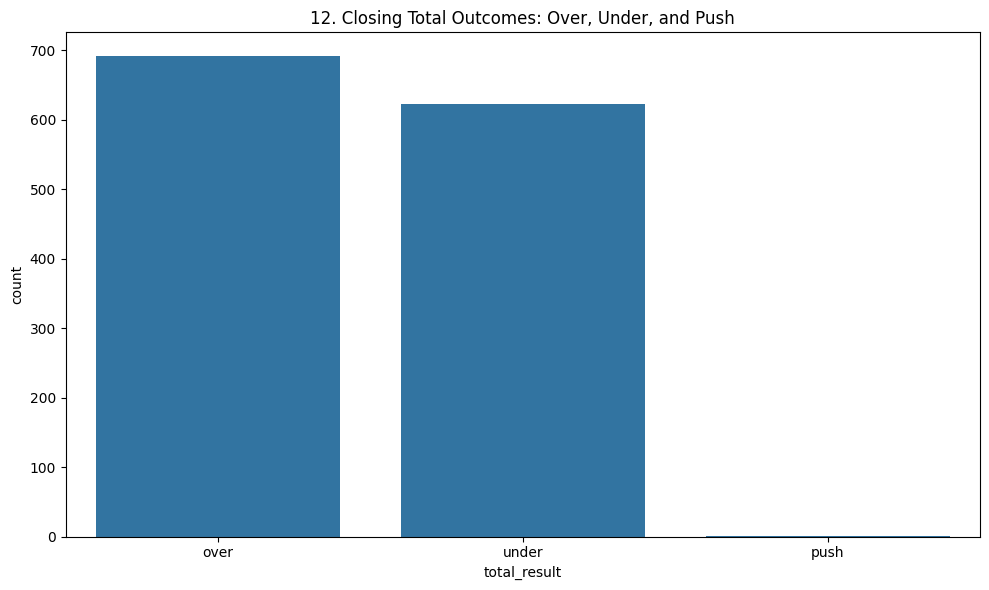

In [25]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='total_result', order=df['total_result'].value_counts().index)
plt.title(f'{plot_no}. Closing Total Outcomes: Over, Under, and Push')
show_fig()
plot_no += 1

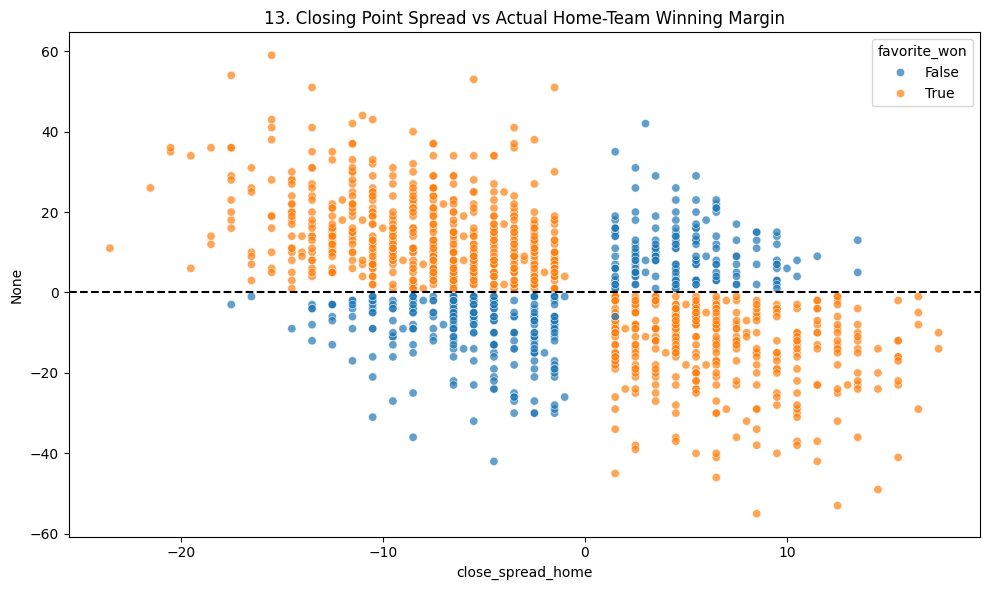

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='close_spread_home', y=df['home_score'] - df['away_score'], hue='favorite_won', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.title(f'{plot_no}. Closing Point Spread vs Actual Home-Team Winning Margin')
show_fig()
plot_no += 1

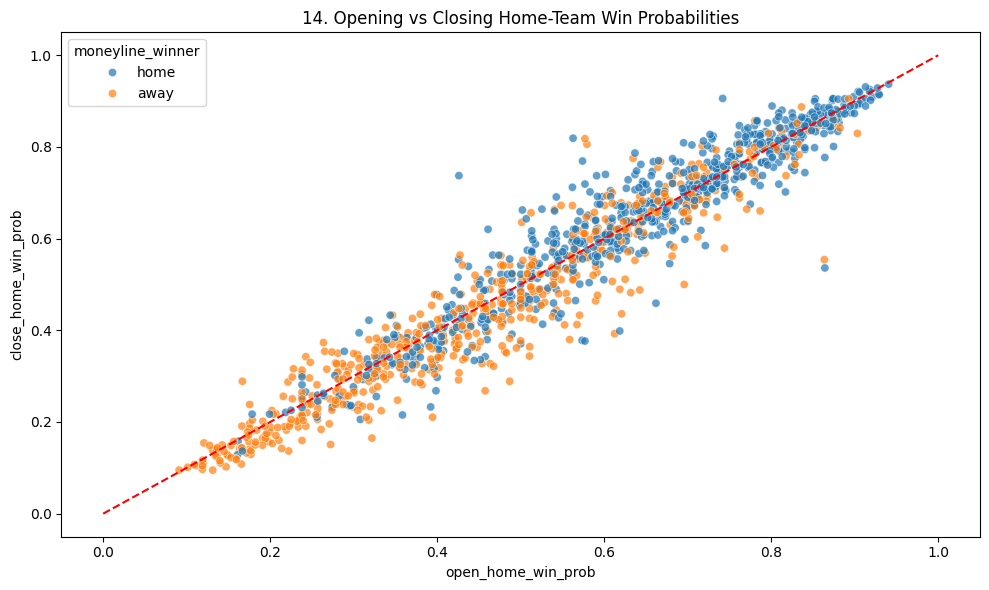

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='open_home_win_prob', y='close_home_win_prob', hue='moneyline_winner', alpha=0.7)
plt.plot([0, 1], [0, 1], linestyle='--', color='red')
plt.title(f'{plot_no}. Opening vs Closing Home-Team Win Probabilities')
show_fig()
plot_no += 1

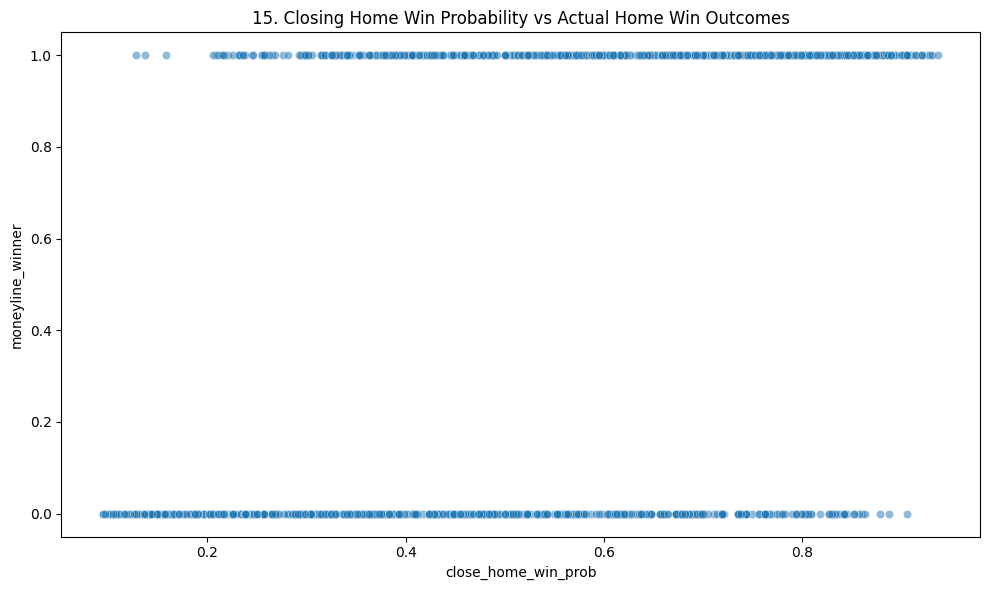

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='close_home_win_prob', y=(df['moneyline_winner'] == 'home').astype(int), alpha=0.5)
plt.title(f'{plot_no}. Closing Home Win Probability vs Actual Home Win Outcomes')
show_fig()
plot_no += 1

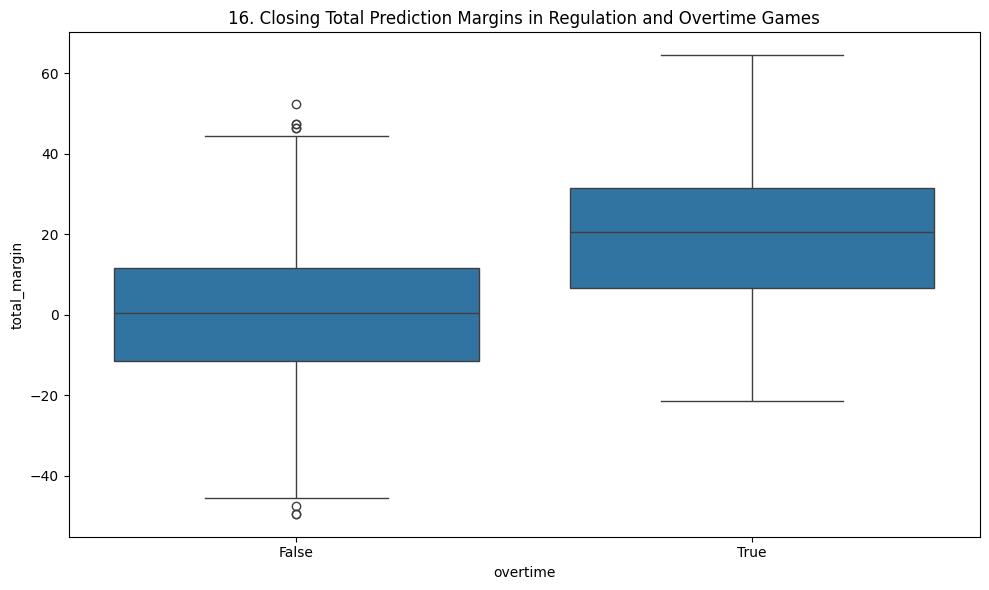

In [29]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='overtime', y='total_margin')
plt.title(f'{plot_no}. Closing Total Prediction Margins in Regulation and Overtime Games')
show_fig()
plot_no += 1

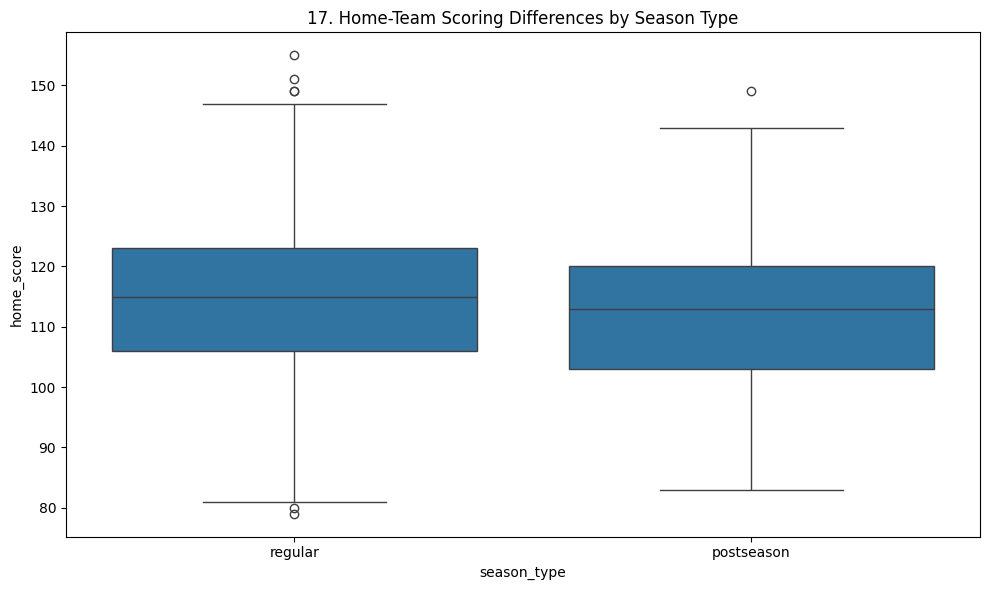

In [30]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='season_type', y='home_score')
plt.title(f'{plot_no}. Home-Team Scoring Differences by Season Type')
show_fig()
plot_no += 1

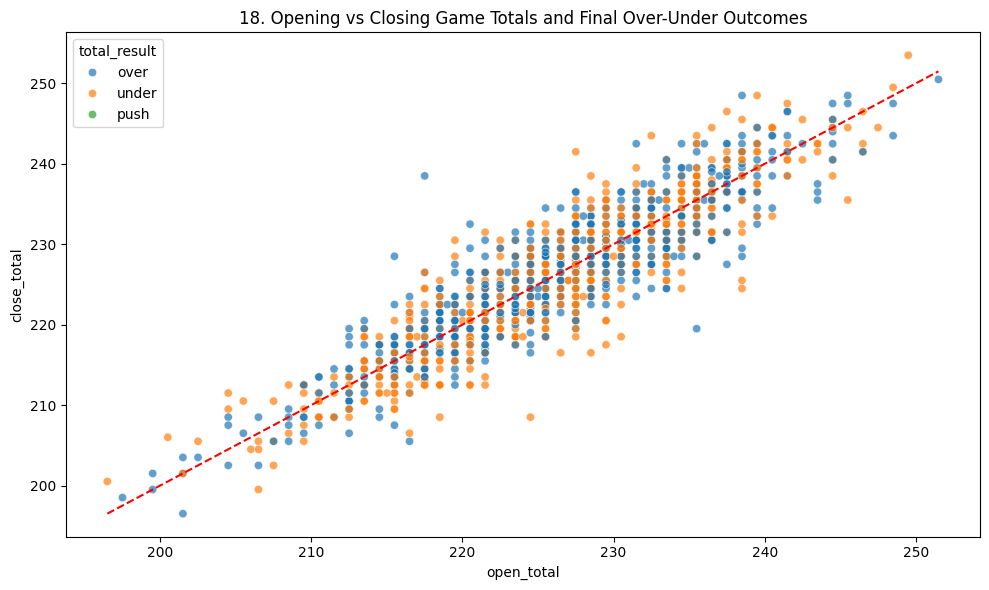

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='open_total', y='close_total', hue='total_result', alpha=0.7)
plt.plot([df['open_total'].min(), df['open_total'].max()], [df['open_total'].min(), df['open_total'].max()], color='red', linestyle='--')
plt.title(f'{plot_no}. Opening vs Closing Game Totals and Final Over-Under Outcomes')
show_fig()
plot_no += 1

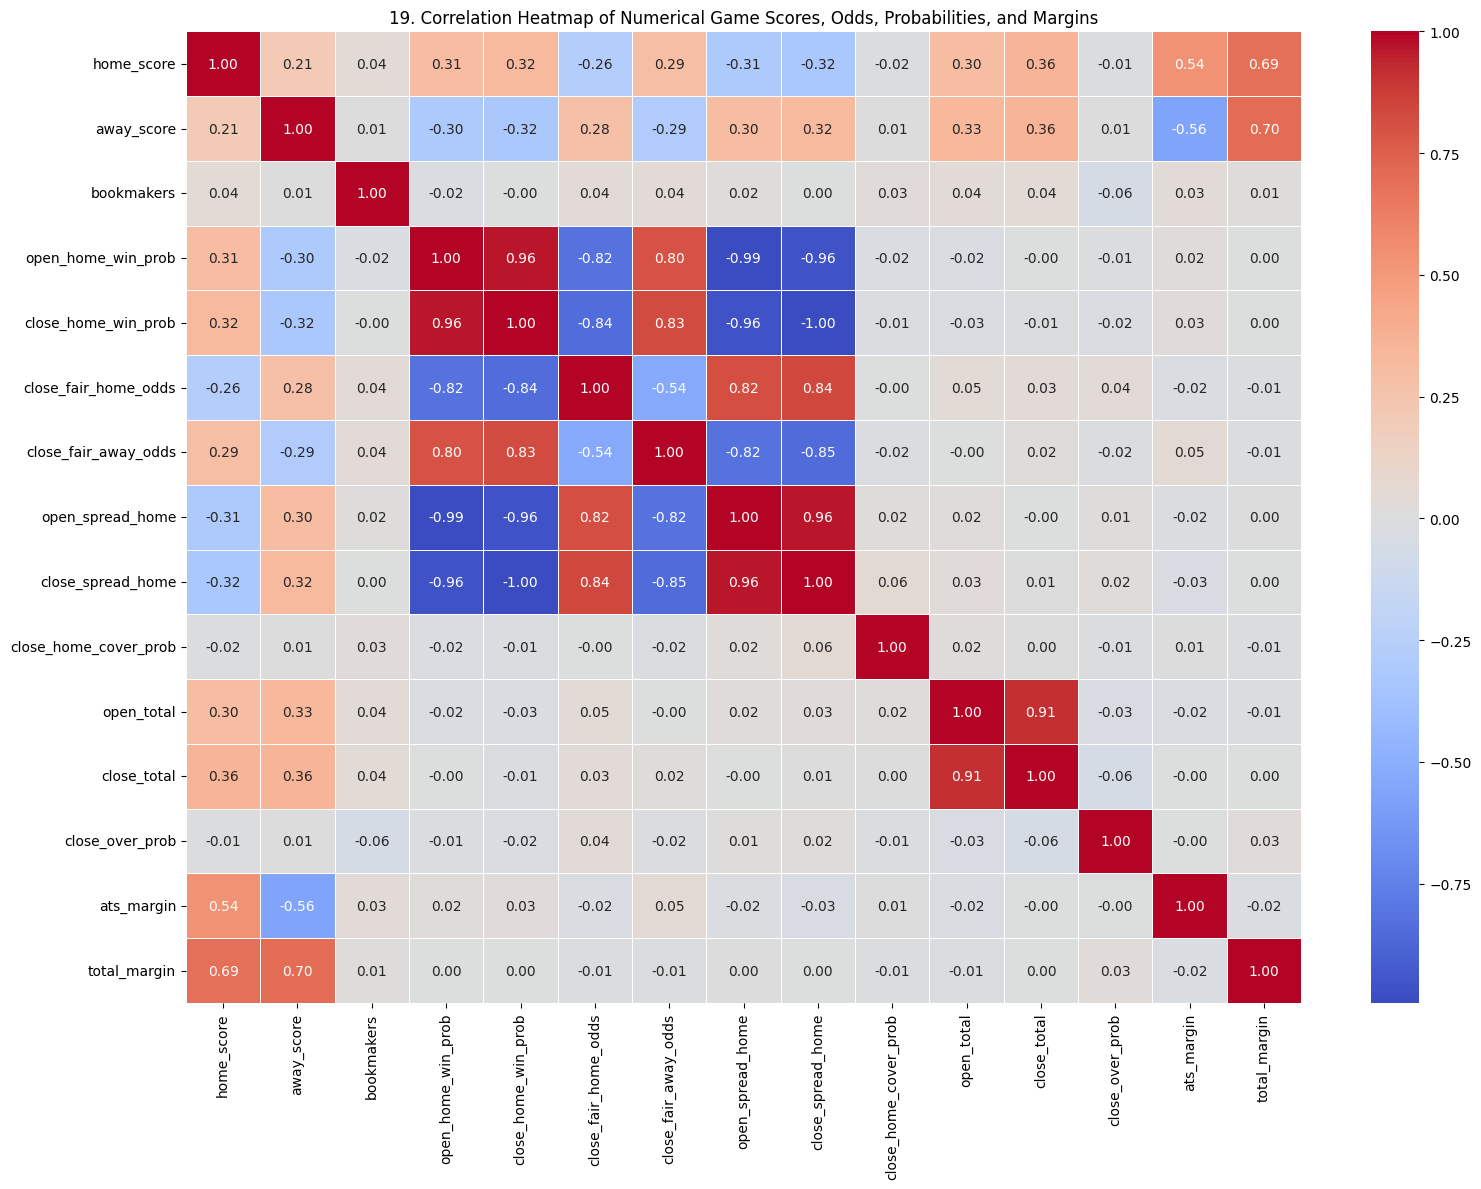

In [32]:
corr = df.select_dtypes(include='number').corr()
fig = plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Game Scores, Odds, Probabilities, and Margins')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [33]:
data = df.copy()
data = data.dropna(subset=['moneyline_winner'])
data = data.drop(columns=[
    'game_id', 'date_et', 'start_time_utc',
    'home_score', 'away_score', 'favorite_won',
    'ats_result', 'ats_margin', 'ats_result_open',
    'total_result', 'total_margin', 'total_result_open'
], errors='ignore')

## Select numerical features

In [34]:
X = data.drop(columns=['moneyline_winner'])
X = X.select_dtypes(include=np.number)
X = X.replace([np.inf, -np.inf], np.nan)
y = LabelEncoder().fit_transform(data['moneyline_winner'])

## Split the dataset

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Handle missing values and scale features

In [36]:
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train = scaler.fit_transform(imputer.fit_transform(X_train))
X_test = scaler.transform(imputer.transform(X_test))

## Build the neural network

In [37]:
tf.keras.utils.set_random_seed(42)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.25),
    Dense(32, activation='relu'),
    Dropout(0.15),
    Dense(len(np.unique(y)), activation='softmax')
])

## Compile the model

In [38]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Train with early stopping

In [39]:
early_stop = EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)
model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6131 - loss: 0.6503 - val_accuracy: 0.7014 - val_loss: 0.6011
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6726 - loss: 0.6040 - val_accuracy: 0.7014 - val_loss: 0.5938
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6857 - loss: 0.6015 - val_accuracy: 0.7062 - val_loss: 0.5896
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6750 - loss: 0.5955 - val_accuracy: 0.7109 - val_loss: 0.5905
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6905 - loss: 0.5951 - val_accuracy: 0.7062 - val_loss: 0.5865
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6738 - loss: 0.5796 - val_accuracy: 0.7156 - val_loss: 0.5834
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6786 - loss: 0.5853 - val_accuracy: 0.7156 - val_loss: 0.5844
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6905 - loss: 0.5820 - val_accuracy: 0.7156

## Evaluate testing accuracy only

In [40]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Testing Accuracy: {test_accuracy:.2%}")

Testing Accuracy: 63.12%


## Predict testing outcomes

In [41]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print("\nTesting Classification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Testing Classification Report:

              precision    recall  f1-score   support

           0       0.61      0.54      0.57       120
           1       0.65      0.71      0.68       143

    accuracy                           0.63       263
   macro avg       0.63      0.62      0.62       263
weighted avg       0.63      0.63      0.63       263



## Plot the testing confusion matrix

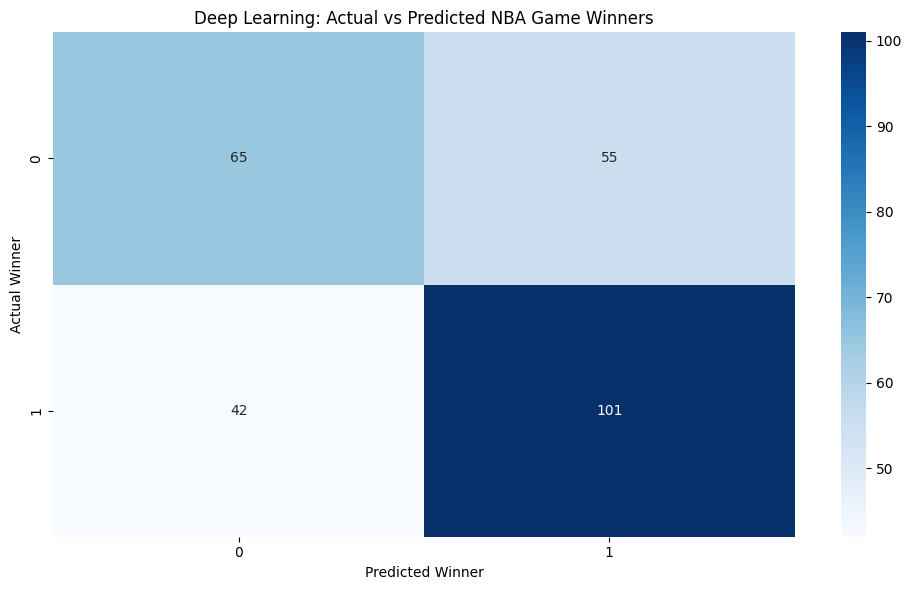

In [42]:
cm = confusion_matrix(y_test, y_pred)
fig = plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Winner')
plt.ylabel('Actual Winner')
plt.title('Deep Learning: Actual vs Predicted NBA Game Winners')
show_fig()

In [43]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             768 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 2)                   │              66 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,744 (34.16 KB)

 Trainable params: 2,914 (11.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,830 (22.78 KB)